# Fire2Air Darwin — Assessment 3
## 05 Visualisation, Integration, Tomorrow Smoke Outlook and Documentation
**Member:** Dieu Yen Diep

Assessment 3 upgrades:
- visualises FSI, aligned/upwind FRP and next-day PM2.5 relationships;
- consolidates model, station, cross-station and ablation results;
- integrates the three predictions into a station-specific Tomorrow Smoke Outlook;
- creates dashboard-ready decision-support output with explicit reliability rules;
- updates the evidence manifest and README for the Assessment 3 run order;
- keeps API/dashboard deployment as optional future layers unless actually implemented.

In [20]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

possible_folders = [Path.cwd(), Path.cwd() / "Data Science", Path.home() / "Desktop" / "Data Science"]

In [21]:
from pathlib import Path

project_folder = Path(
    r"C:\Users\khuep\Desktop\PRT661---DATA-SCIENCE-PRACTICE---Dan5---Theme2\Source code\outputs_prt661\processed"
)

print("File exists:", (project_folder / "Fire2Air_model_ready_checkpoint_A3.csv").exists())

output_root = project_folder / "outputs_prt661_a3"
table_dir = output_root / "tables"
figure_dir = output_root / "figures"
for folder in [table_dir, figure_dir]:
    folder.mkdir(parents=True, exist_ok=True)

model_table = pd.read_csv(
    project_folder / "Fire2Air_model_ready_checkpoint_A3.csv",
    parse_dates=["date", "target_date"],
)
daily_air = pd.read_csv(
    project_folder / "Fire2Air_ntepa_daily_checkpoint_A3.csv",
    parse_dates=["date"],
)
fire_daily = pd.read_csv(
    project_folder / "Fire2Air_firms_daily_checkpoint_A3.csv",
    parse_dates=["date_darwin"],
)
manifest_path = (
    project_folder.parent
    / "metadata"
    / "Fire2Air_feature_manifest_A3.json"
)

with open(manifest_path, "r", encoding="utf-8") as f:
    manifest = json.load(f)

model_features = manifest["features"]
PM25_THRESHOLD = float(manifest["threshold_pm25_ug_m3"])
MAX_FIRE_DISTANCE_KM = float(manifest["max_fire_distance_km"])

print("Project folder:", project_folder)
print("Model-ready rows:", len(model_table))
print("Predictors:", len(model_features))

File exists: True
Project folder: C:\Users\khuep\Desktop\PRT661---DATA-SCIENCE-PRACTICE---Dan5---Theme2\Source code\outputs_prt661\processed
Model-ready rows: 7530
Predictors: 93


## A. Updated Assessment 3 architecture

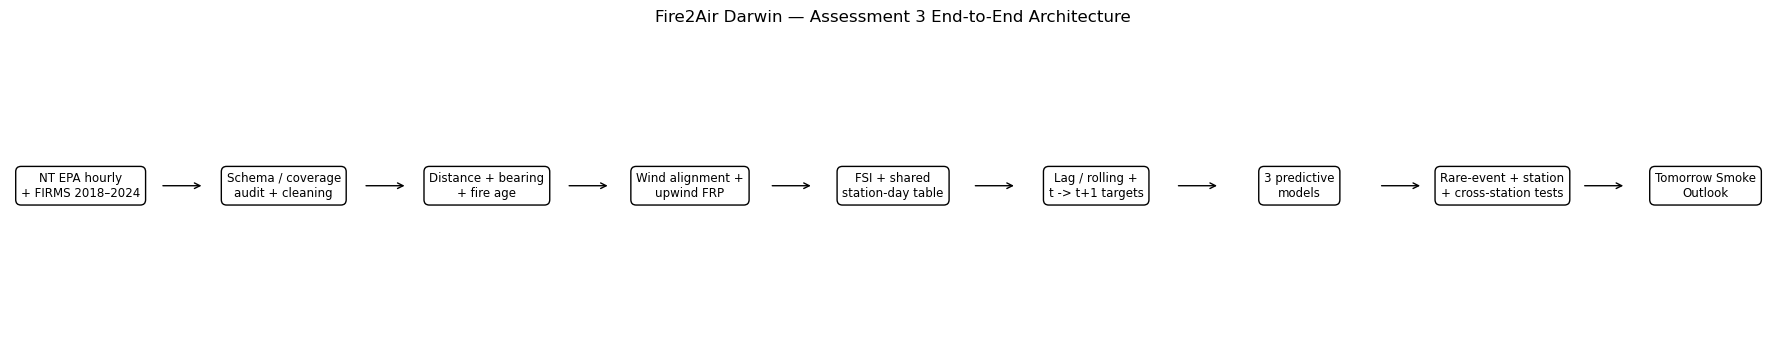

In [22]:
stages = [
    "NT EPA hourly\n+ FIRMS 2018–2024",
    "Schema / coverage\naudit + cleaning",
    "Distance + bearing\n+ fire age",
    "Wind alignment +\nupwind FRP",
    "FSI + shared\nstation-day table",
    "Lag / rolling +\nt -> t+1 targets",
    "3 predictive\nmodels",
    "Rare-event + station\n+ cross-station tests",
    "Tomorrow Smoke\nOutlook",
]
fig, ax = plt.subplots(figsize=(18, 3.5))
ax.axis("off")
xs = np.linspace(0.04, 0.96, len(stages))
for i, (x, label) in enumerate(zip(xs, stages)):
    ax.text(
        x, 0.5, label, ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.45", fc="white", ec="black"),
        transform=ax.transAxes, fontsize=8.5,
    )
    if i < len(stages) - 1:
        ax.annotate(
            "", xy=(xs[i + 1] - 0.045, 0.5), xytext=(x + 0.045, 0.5),
            xycoords=ax.transAxes, textcoords=ax.transAxes,
            arrowprops=dict(arrowstyle="->"),
        )
ax.set_title("Fire2Air Darwin — Assessment 3 End-to-End Architecture", pad=14)
fig.tight_layout()
fig.savefig(figure_dir / "a3_01_updated_architecture.png", dpi=180, bbox_inches="tight")
plt.show()

## B. Core EDA: PM2.5 trend, station distribution and exceedance frequency

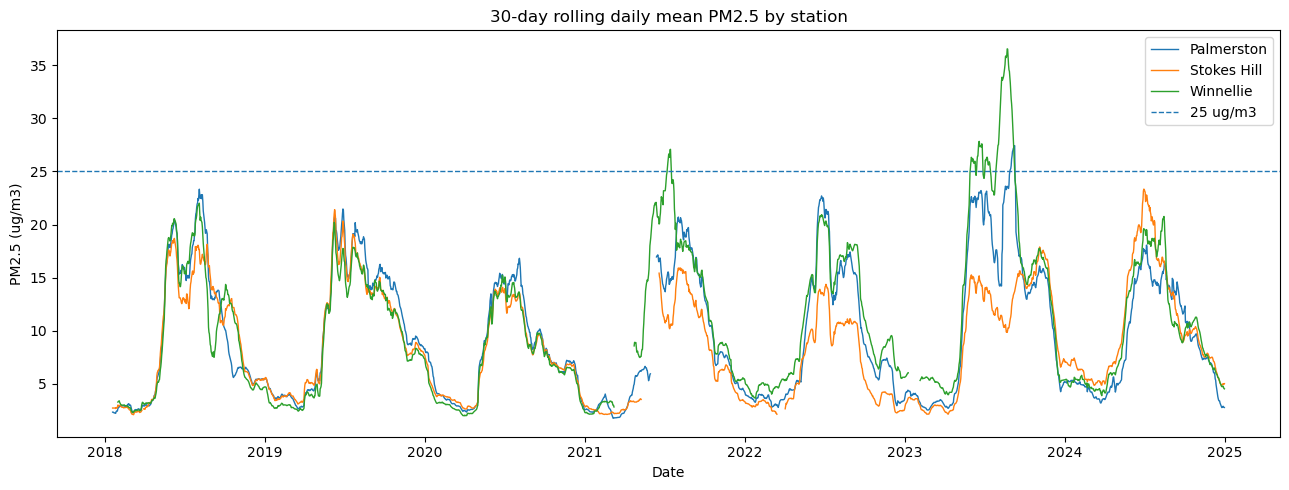

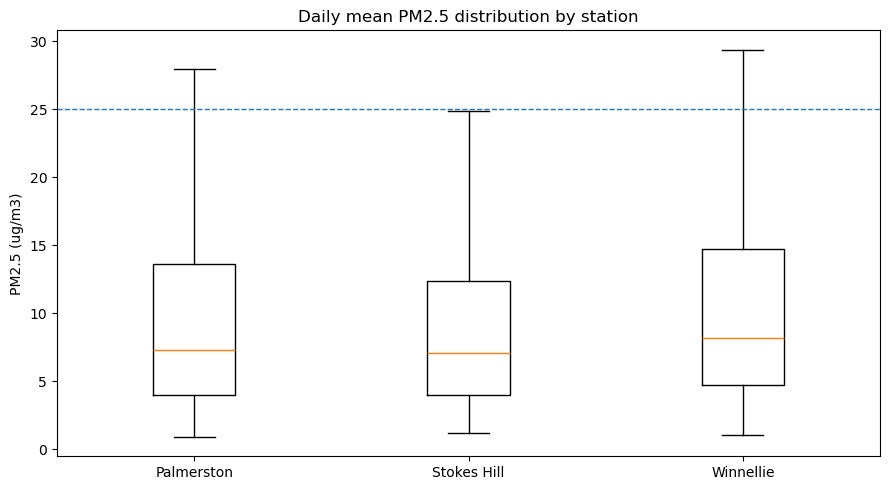

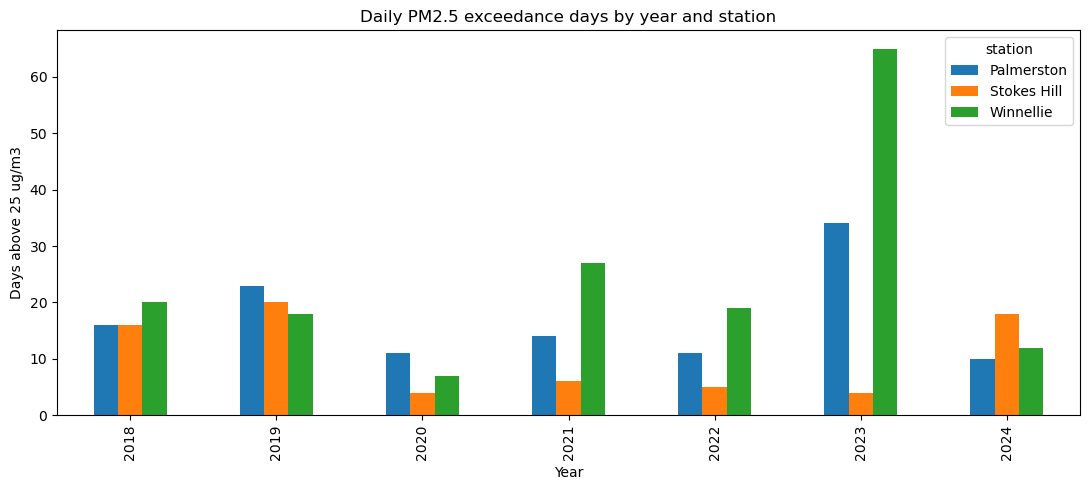

In [23]:
fig, ax = plt.subplots(figsize=(13, 5))
for station, g in daily_air.sort_values("date").groupby("station"):
    smoothed = g.set_index("date")["pm25_mean"].rolling(30, min_periods=10).mean()
    ax.plot(smoothed.index, smoothed.values, label=station, linewidth=1)
ax.axhline(PM25_THRESHOLD, linestyle="--", linewidth=1, label="25 ug/m3")
ax.set_title("30-day rolling daily mean PM2.5 by station")
ax.set_xlabel("Date")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "a3_02_pm25_trend_by_station.png", dpi=180, bbox_inches="tight")
plt.show()

stations = sorted(daily_air["station"].dropna().unique())
data = [daily_air.loc[daily_air["station"].eq(s), "pm25_mean"].dropna() for s in stations]
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(data, tick_labels=stations, showfliers=False)
ax.axhline(PM25_THRESHOLD, linestyle="--", linewidth=1)
ax.set_title("Daily mean PM2.5 distribution by station")
ax.set_ylabel("PM2.5 (ug/m3)")
fig.tight_layout()
fig.savefig(figure_dir / "a3_03_pm25_distribution_by_station.png", dpi=180, bbox_inches="tight")
plt.show()

exceedance_counts = (
    daily_air.dropna(subset=["pm25_mean"])
    .assign(year=lambda d: d["date"].dt.year, exceedance=lambda d: (d["pm25_mean"] > PM25_THRESHOLD).astype(int))
    .groupby(["year", "station"])["exceedance"].sum()
    .unstack("station").fillna(0)
)
ax = exceedance_counts.plot(kind="bar", figsize=(11, 5))
ax.set_title("Daily PM2.5 exceedance days by year and station")
ax.set_xlabel("Year")
ax.set_ylabel("Days above 25 ug/m3")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(figure_dir / "a3_04_exceedance_days_by_year_station.png", dpi=180, bbox_inches="tight")
plt.show()